## 1. Load Dependencies
We import the core libraries needed for working with the dataset, visualizing images, and handling file paths.

In [2]:
import yaml
import pathlib
import cv2
import matplotlib.pyplot as plt

plt.style.use('ggplot')

In [3]:
# Update dataset root path
DATASET_ROOT = pathlib.Path('/Users/muhammedshibil/Documents/projects/Car Damage Analyzer/Data/Car Damage')
DATA_YAML_PATH = DATASET_ROOT / 'data.yaml'

## 2. Load dataset YAML
Read the dataset configuration file to extract the split locations and the ordered list of class names.

In [5]:
DATASET_ROOT = pathlib.Path('/Users/muhammedshibil/Documents/projects/Car Damage Analyzer/Data/Car Damage')
DATA_YAML_PATH = DATASET_ROOT / 'data.yaml'

with DATA_YAML_PATH.open('r', encoding='utf-8') as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg.get('names', [])
num_classes = data_cfg.get('nc', len(class_names))

print(f'Class names: {class_names}')
print(f'Number of classes: {num_classes}')

Class names: ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']
Number of classes: 6


## 3. Count Images in Train / Val / Test Splits
Count how many `.jpg` and `.png` images exist inside each split's image directory.

In [6]:
def count_images(split_name):
    image_dir = DATASET_ROOT / split_name / 'images'
    if not image_dir.exists():
        raise FileNotFoundError(f'Missing directory: {image_dir}')
    jpg_count = len(list(image_dir.glob('*.jpg')))
    png_count = len(list(image_dir.glob('*.png')))
    return jpg_count, png_count

splits = ['train', 'val', 'test']
image_counts = {}
for split in splits:
    jpg_count, png_count = count_images(split)
    total = jpg_count + png_count
    image_counts[split] = {
        'jpg': jpg_count,
        'png': png_count,
        'total': total
    }
    print(f"{split.title()} split -> JPG: {jpg_count}, PNG: {png_count}, Total: {total}")

image_counts

Train split -> JPG: 2816, PNG: 0, Total: 2816
Val split -> JPG: 810, PNG: 0, Total: 810
Test split -> JPG: 374, PNG: 0, Total: 374


{'train': {'jpg': 2816, 'png': 0, 'total': 2816},
 'val': {'jpg': 810, 'png': 0, 'total': 810},
 'test': {'jpg': 374, 'png': 0, 'total': 374}}

## 4. Validate Image-Label Pairing
Ensure each image has a matching YOLO label text file and vice versa.

In [7]:
def validate_pairs(split_name):
    image_dir = DATASET_ROOT / split_name / 'images'
    label_dir = DATASET_ROOT / split_name / 'labels'
    if not image_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f'Missing directory for split {split_name}')
    image_files = sorted([p for p in image_dir.iterdir() if p.suffix.lower() in {'.jpg', '.png'}])
    label_files = sorted(label_dir.glob('*.txt'))

    image_stems = {p.stem for p in image_files}
    label_stems = {p.stem for p in label_files}

    missing_labels = sorted([img.name for img in image_files if img.stem not in label_stems])
    missing_images = sorted([lbl.name for lbl in label_files if lbl.stem not in image_stems])

    return missing_labels, missing_images

for split in splits:
    missing_labels, missing_images = validate_pairs(split)
    print(f'=== {split.title()} Split ===')
    print('Images without labels:', missing_labels if missing_labels else 'None')
    print('Labels without images:', missing_images if missing_images else 'None')
    print()

=== Train Split ===
Images without labels: None
Labels without images: None

=== Val Split ===
Images without labels: None
Labels without images: None

=== Test Split ===
Images without labels: None
Labels without images: None



## 5. Visualize Sample Images with YOLO Bounding Boxes
Define a helper to plot YOLO annotations and preview five training images.

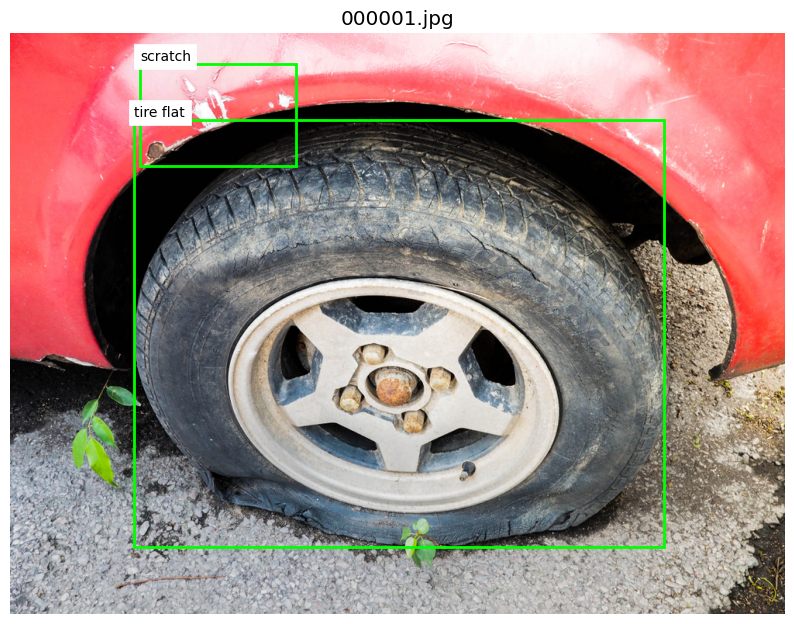

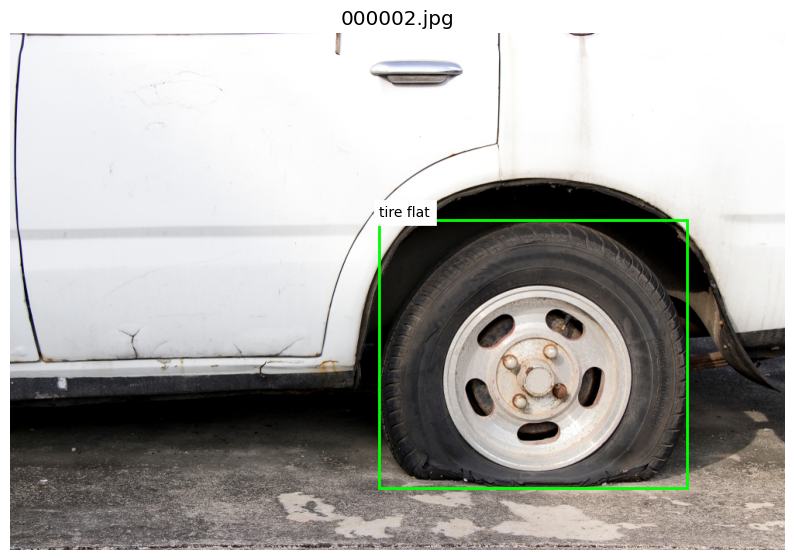

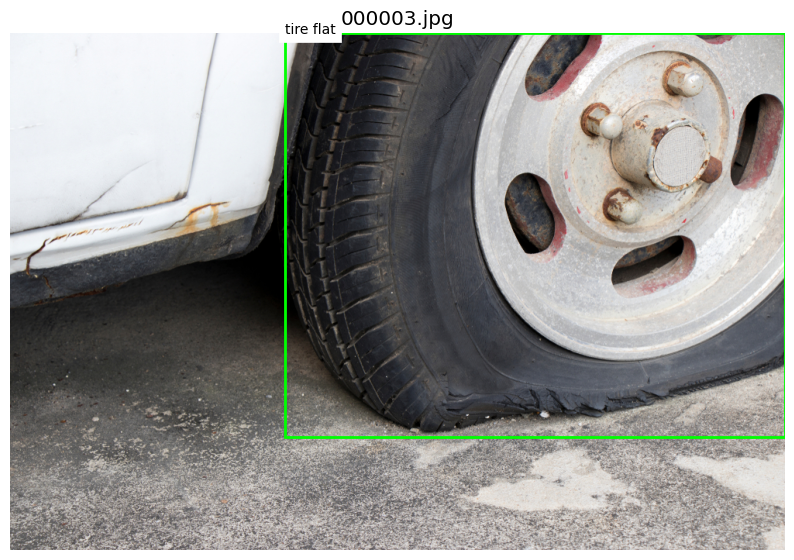

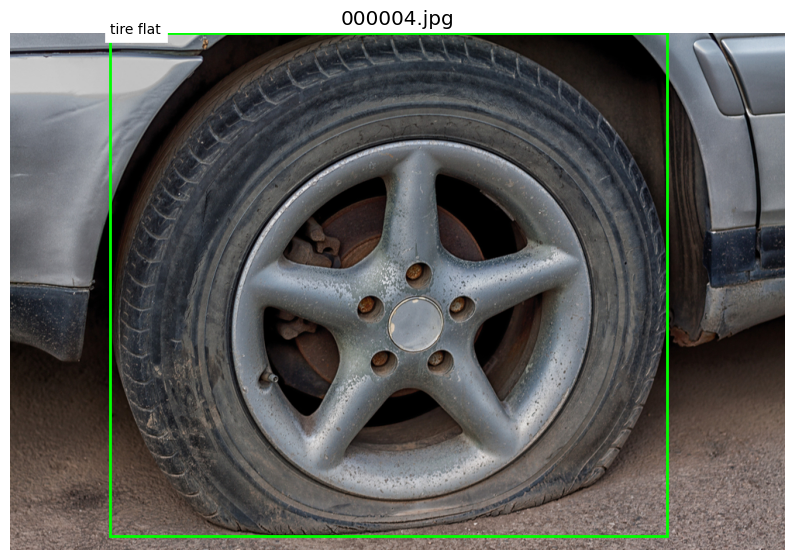

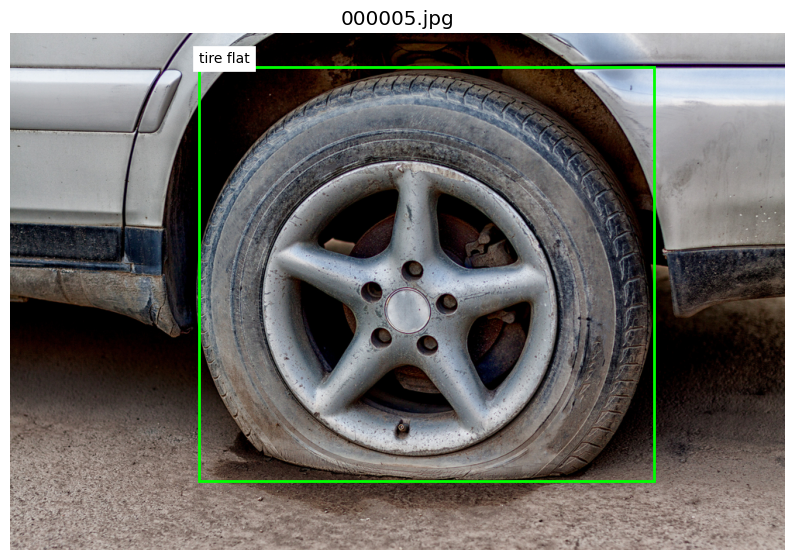

In [8]:
def yolo_to_xyxy(box, img_w, img_h):
    x_center, y_center, box_w, box_h = box
    w_px = box_w * img_w
    h_px = box_h * img_h
    x1 = max(0, int((x_center * img_w) - (w_px / 2)))
    y1 = max(0, int((y_center * img_h) - (h_px / 2)))
    x2 = min(img_w - 1, int(x1 + w_px))
    y2 = min(img_h - 1, int(y1 + h_px))
    return x1, y1, x2, y2

def show_yolo_image(img_path, label_path, class_names):
    image = cv2.imread(str(img_path))
    if image is None:
        raise FileNotFoundError(f'Unable to read image: {img_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    img_h, img_w = image.shape[:2]

    annotations = []
    if label_path.exists():
        with label_path.open('r', encoding='utf-8') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls_id = int(float(parts[0]))
                box = tuple(float(v) for v in parts[1:])
                annotations.append((cls_id, box))

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image)
    ax.set_title(img_path.name)
    ax.axis('off')

    for cls_id, box in annotations:
        x1, y1, x2, y2 = yolo_to_xyxy(box, img_w, img_h)
        width, height = x2 - x1, y2 - y1
        rect = plt.Rectangle((x1, y1), width, height, edgecolor='lime', facecolor='none', linewidth=2)
        ax.add_patch(rect)
        label = class_names[cls_id] if 0 <= cls_id < len(class_names) else f'class {cls_id}'
        ax.text(x1, max(0, y1 - 5), label, color='black', fontsize=10, backgroundcolor='white')

    plt.show()

train_image_dir = DATASET_ROOT / 'train' / 'images'
train_label_dir = DATASET_ROOT / 'train' / 'labels'
train_images = sorted([p for p in train_image_dir.iterdir() if p.suffix.lower() in {'.jpg', '.png'}])

if not train_images:
    print('No training images found to visualize.')
else:
    for img_path in train_images[:5]:
        label_path = train_label_dir / f"{img_path.stem}.txt"
        show_yolo_image(img_path, label_path, class_names)

## 6. Summary Section (Markdown)
Use this section to jot down insights such as number of classes, names, dataset size per split, and any annotation quality observations.